In [27]:
import sys
from pathlib import Path
import json

if Path.cwd().name == "notebooks":
    import os
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf
from sklearn.feature_extraction.text import CountVectorizer

from data import load_config, get_processed_corpus, variant_dir
from data import parse_running_header

#### 1. Data loading and saving data files

In [28]:
cfg = load_config()
data_cfg = cfg["data"]

In [29]:
cfg = load_config()
data_cfg = cfg["data"]

# margins check based on running headers and footers
pdf_path = Path(cfg["paths"]["raw_dir"]) / data_cfg["variants"]["v1"]["pdf_file"]
header_bottoms = []
footer_heights = []

with pymupdf.open(pdf_path) as doc:
    for page in doc:
        for block in page.get_text("blocks"):
            flat = " ".join(block[4].split())
            if parse_running_header(flat):
                header_bottoms.append(block[3])
            elif flat.lower().startswith("access for free"):
                footer_heights.append(page.rect.height - block[1])

if header_bottoms:
    print(f"Suggested top_margin >= {round(max(header_bottoms) + 2)}")
if footer_heights:
    print(f"Suggested bottom_margin >= {round(max(footer_heights) + 2)}")

# Process corpora for all variants and save to interim
corpora = {variant: get_processed_corpus(cfg, variant=variant) for variant in data_cfg["variants"]}

for variant, corpus in corpora.items():
    words = sum(len(r["text"].split()) for r in corpus)
    print(f"Variant {variant}: {len(corpus)} paragraphs, {words} words -> saved in: {variant_dir(cfg, variant)}")

Suggested top_margin >= 36
Suggested bottom_margin >= 36
Variant v1: 355 paragraphs, 27006 words -> saved in: data\interim\v1
Variant v2: 401 paragraphs, 28130 words -> saved in: data\interim\v2


#### 2. Quality of Text Cleaning & Tables

In [30]:
df = pd.DataFrame(corpora["v1"])
df["n_words"] = df["text"].str.split().str.len()

# Check for unwanted patterns
checks = {
    "links / footers": r"https?://|openstax\.org",
    "figure / table markers": r"\b(?:FIGURE|TABLE) \d",
    "double spaces": r"  ",
}

print("== Noise Check ==")
for name, pattern in checks.items():
    hits = df[df["text"].str.contains(pattern, regex=True)]
    print(f"{name}: {len(hits)} paragraphs matching the pattern")
    for text in hits["text"].head(2):
        print(f"   -> {text[:120]}")

# Check processed tables
table_like = df[df["text"].str.contains(r":.*;", regex=True)]
print(f"\nFound {len(table_like)} processed table rows:\n")
for text in table_like["text"].head(10):
    print("-", text)

== Noise Check ==
links / footers: 0 paragraphs matching the pattern
figure / table markers: 0 paragraphs matching the pattern
double spaces: 0 paragraphs matching the pattern

Found 16 processed table rows:

- Thenationalgovernmentcouldnot imposetaxesoncitizens Itcould . onlyrequestmoneyfromthe states .: Thenationalgovernmentcouldnot regulateforeigntradeorinterstate commerce .; Requestsformoneywereusuallynothonored Asaresult thenational . , governmentdidnothavemoneytopayfornationaldefenseorfulfillitsother responsibilities .: ThegovernmentcouldnotpreventforeigncountriesfromhurtingAmerican competitorsbyshippinginexpensiveproductstotheUnitedStates Itcould . notpreventstatesfrompassinglawsthatinterferedwithdomestictrade .
- Thenationalgovernmentcouldnot imposetaxesoncitizens Itcould . onlyrequestmoneyfromthe states .: Thenationalgovernmentcouldnot raiseanarmy Ithadtorequestthe . statestosendmen .; Requestsformoneywereusuallynothonored Asaresult thenational . , governmentdidnothavemoneytop

-----------------------------------------

#### 3. EDA

##### 3.1 Paragraph Length & Distribution

3.1.1 In general

In [38]:
# 5 longest paragraphs
print("--- 5 Longest Paragraphs ---")
longest = df.nlargest(5, "n_words")[["chapter", "section", "printed_page", "n_words", "text"]]
for idx, row in longest.iterrows():
    print(f"== Chapter: {row['chapter']} | Section: {row['section']} | Page: {row['printed_page']} ({row['n_words']} words) ==")
    print(row["text"][:300] + "...\n")

--- 5 Longest Paragraphs ---
== Chapter: 3 | Section: 3.5 Advantages and Disadvantages of Federalism | Page: 94.0 (314 words) ==
The federal design of our Constitution and the system of checks and balances has jeopardized or outright blocked federal responses to important national issues. President Roosevelt’s efforts to combat the scourge of the Great Depression were initially struck down by the Supreme Court. More recently,...

== Chapter: 2 | Section: nan | Page: 32.0 (229 words) ==
Locke was not the first Englishman to suggest that people had rights. The British government had recognized its duty to protect the lives, liberties, and property of English citizens long before the settling of its North American colonies. In 1215, King John signed Magna Carta—a promise to his subje...

== Chapter: 3 | Section: 3.4 Competitive Federalism Today | Page: 88.0 (223 words) ==
In 2012, in Arizona v. United States, the Supreme Court affirmed federal supremacy on immigration. The court struck do

In [39]:
# 5 shortest paragraphs
print("--- 5 Shortest Paragraphs ---")
shortest = df.nsmallest(5, "n_words")[["chapter", "section", "printed_page", "n_words", "text"]]
for idx, row in shortest.iterrows():
    print(f"== Page: {row['printed_page']} ({row['n_words']} words) ==")
    print(row["text"] + "\n")

--- 5 Shortest Paragraphs ---
== Page: 52.0 (1 words) ==
administration.

== Page: 83.0 (1 words) ==
GRANTS

== Page: 94.0 (1 words) ==
redistricting.

== Page: 44.0 (2 words) ==
Three-Fifths Compromise.

== Page: 48.0 (2 words) ==
INSIDER PERSPECTIVE



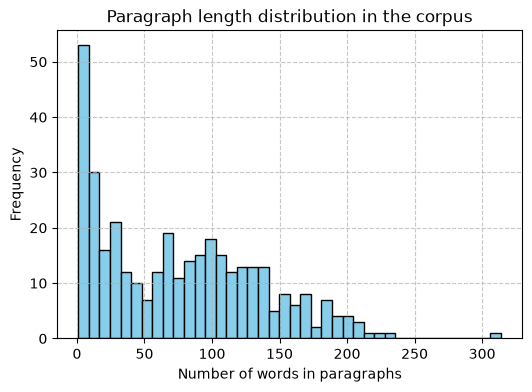

count    355.000000
mean      76.073239
std       60.015255
min        1.000000
25%       20.500000
50%       71.000000
75%      119.000000
max      314.000000
Name: n_words, dtype: float64

In [32]:
# Histogram of paragraph lengths
plt.figure(figsize=(6, 4))
plt.hist(df["n_words"], bins=40, color="skyblue", edgecolor="black")
plt.xlabel("Number of words in paragraphs")
plt.ylabel("Frequency")
plt.title("Paragraph length distribution in the corpus")
Path("reports/figures").mkdir(parents=True, exist_ok=True)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig("reports/figures/paragraph_length_hist.png", dpi=150)
plt.show()

display(df["n_words"].describe())

3.1.2 Section-Level Statistics

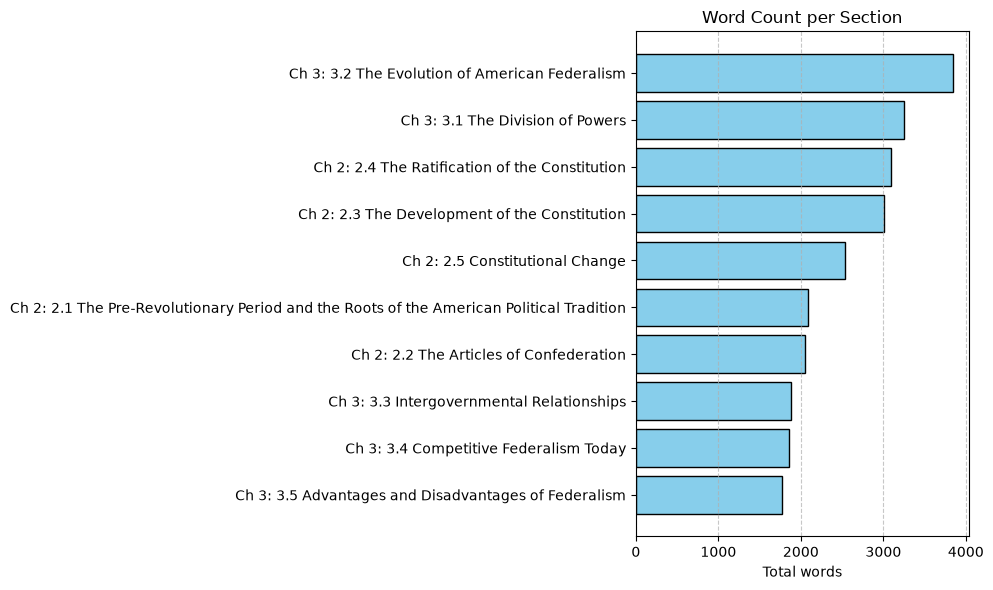

,chapter,section,total_words,paragraph_count,label
9,3,3.5 Advantages and Disadvantages of Federalism,1767,34,Ch 3: 3.5 Advantages and Disadvantages of Fede...
8,3,3.4 Competitive Federalism Today,1860,26,Ch 3: 3.4 Competitive Federalism Today
7,3,3.3 Intergovernmental Relationships,1886,20,Ch 3: 3.3 Intergovernmental Relationships
1,2,2.2 The Articles of Confederation,2051,34,Ch 2: 2.2 The Articles of Confederation
0,2,2.1 The Pre-Revolutionary Period and the Roots...,2082,22,Ch 2: 2.1 The Pre-Revolutionary Period and the...
4,2,2.5 Constitutional Change,2531,37,Ch 2: 2.5 Constitutional Change
2,2,2.3 The Development of the Constitution,3003,41,Ch 2: 2.3 The Development of the Constitution
3,2,2.4 The Ratification of the Constitution,3094,34,Ch 2: 2.4 The Ratification of the Constitution
5,3,3.1 The Division of Powers,3256,33,Ch 3: 3.1 The Division of Powers
6,3,3.2 The Evolution of American Federalism,3843,47,Ch 3: 3.2 The Evolution of American Federalism


In [33]:
section_stats = df.groupby(["chapter", "section"]).agg(
    total_words=("n_words", "sum"),
    paragraph_count=("text", "size")
).reset_index()

section_stats["label"] = "Ch " + section_stats["chapter"].astype(str) + ": " + section_stats["section"].astype(str)
section_stats = section_stats.sort_values(by="total_words", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(section_stats["label"], section_stats["total_words"], color="skyblue", edgecolor="black")
plt.xlabel("Total words")
plt.title("Word Count per Section")
plt.tight_layout()
plt.grid(axis="x", linestyle='--', alpha=0.7)
plt.savefig("reports/figures/section_word_counts.png", dpi=150)
plt.show()

display(section_stats)

- **Section Size:** The length of each section varies a lot. Section 3.2 is the biggest (about 3800 words in 47 paragraphs) and serves as the main core of the material, while Section 3.5 is shorter (about 1700 words in 34 paragraphs).
- **Structure:** Most sections have between 2000 and 3200 words, giving our search system a well-balanced amount of content.

##### 3.2. Term Frequency: Top 20 Overall & Top 10 per Chapter

3.2.1 in general (all corpus)

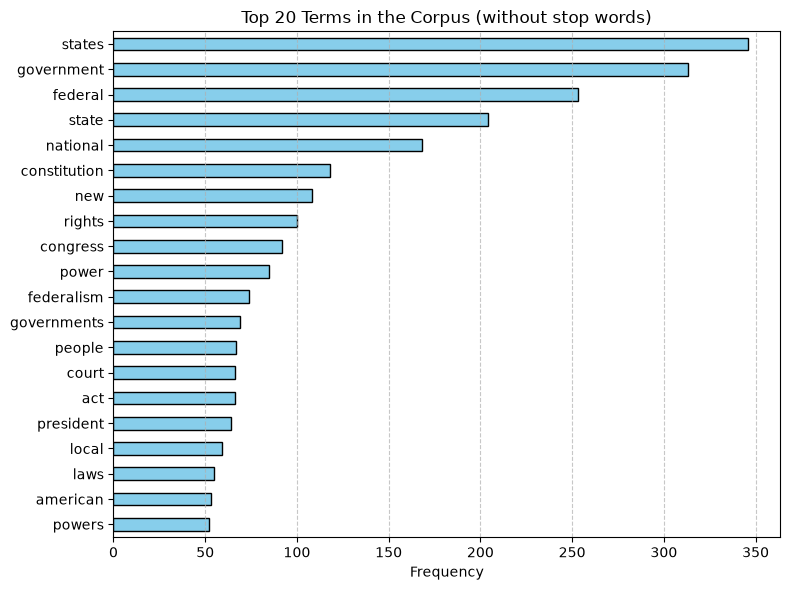

In [34]:
vectorizer = CountVectorizer(stop_words="english")

# Top 20 overall terms
counts_all = vectorizer.fit_transform(df["text"]).sum(axis=0).A1
top_terms_all = pd.Series(counts_all, index=vectorizer.get_feature_names_out()).nlargest(20)

plt.figure(figsize=(8, 6))
top_terms_all.sort_values().plot.barh(color="skyblue", edgecolor="black")
plt.title("Top 20 Terms in the Corpus (without stop words)")
plt.xlabel("Frequency")
plt.tight_layout()
plt.grid(axis="x", linestyle='--', alpha=0.7)
plt.savefig("reports/figures/top_terms_all.png", dpi=150)
plt.show()

3.2.2 per each chapter

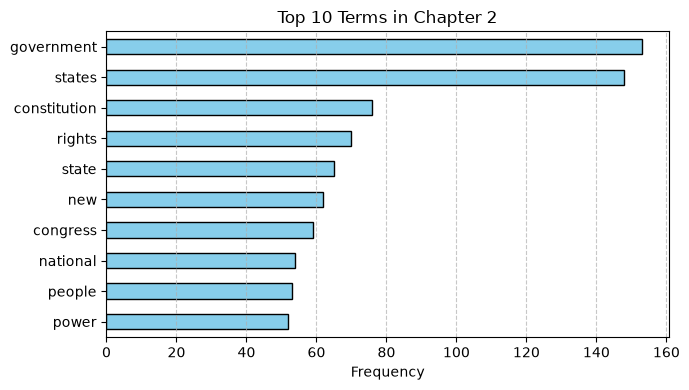

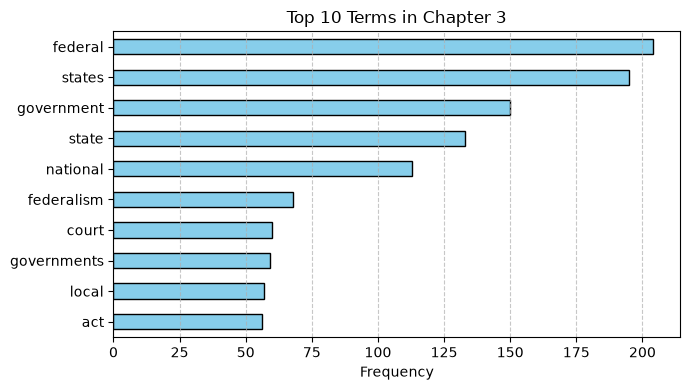

In [35]:
# Top 10 per chapter
chapters = df["chapter"].dropna().unique()
for ch in chapters:
    ch_text = df[df["chapter"] == ch]["text"]
    counts_ch = vectorizer.fit_transform(ch_text).sum(axis=0).A1
    top_terms_ch = pd.Series(counts_ch, index=vectorizer.get_feature_names_out()).nlargest(10)
    
    plt.figure(figsize=(7, 4))
    top_terms_ch.sort_values().plot.barh(color="skyblue", edgecolor="black")
    plt.title(f"Top 10 Terms in Chapter {ch}")
    plt.xlabel("Frequency")
    plt.tight_layout()
    plt.grid(axis="x", linestyle='--', alpha=0.7)
    plt.savefig(f"reports/figures/top_terms_chapter_{ch}.png", dpi=150)
    plt.show()

##### 3.3. Evaluation Dataset Verification

In [41]:
eval_json_path = Path("data/processed/eval_dataset_ch2_3.json")
if eval_json_path.exists():
    with open(eval_json_path, encoding="utf-8") as f:
        eval_data = json.load(f)
    
    print(f"Total chapters in eval set: {len(eval_data.get('chapters', []))}")
    
    for ch in eval_data.get("chapters", []):
        ch_no = ch.get("chapter")
        sum_count = len(ch.get("summaries", []))
        rq_count = len(ch.get("review_questions", []))
        ct_count = len(ch.get("critical_thinking_questions", []))
        kt_count = len(ch.get("key_terms", []))
        print(f"- Chapter {ch_no}: summaries={sum_count}, review_q={rq_count}, critical_thinking={ct_count}, key_terms={kt_count}")
else:
    print("Evaluation dataset file not found in data/processed/")

Total chapters in eval set: 2
- Chapter 2: summaries=5, review_q=15, critical_thinking=7, key_terms=23
- Chapter 3: summaries=5, review_q=19, critical_thinking=5, key_terms=22


#### 4. Summary

- We removed unwanted page numbers, links, and headers. Tables were converted into smooth, easy-to-read sentences.
- The most common words (`states`, `government`, `federal`, `constitution`) accurately reflect the core topic of American law and federalism.